In [2]:
from langgraph.graph import StateGraph,START,END
from pydantic import BaseModel
from typing import Literal

In [3]:
class OrderModel(BaseModel):
    order_amount: float
    shipping_type: Literal["standard", "express"] = ""

In [4]:
def express_shipping(order: OrderModel):
    print("Eligible for express shipping")
    return {"shipping_type": "express"}

def standard_shipping(order: OrderModel):
    print("Eligible for standard shipping")
    return {"shipping_type": "standard"}
    
def routing_order(order: OrderModel):
    if(order.order_amount > 1000):
        return "express_shipping"
    else:
        return "standard_shipping"

In [5]:
graph = StateGraph(OrderModel)

graph.add_node('express_shipping', express_shipping)
graph.add_node('standard_shipping', standard_shipping)

graph.add_conditional_edges(START, routing_order, {'express_shipping': 'express_shipping', 'standard_shipping': 'standard_shipping'})

graph.add_edge('express_shipping', END)
graph.add_edge('standard_shipping', END)

workflow = graph.compile()

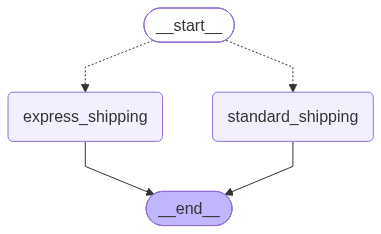

In [6]:
from IPython.display import Image, display
display(Image(workflow.get_graph().draw_mermaid_png()))

In [8]:
initial_state = { "order_amount": 1000 }
result = workflow.invoke(initial_state)
print(result)

Eligible for standard shipping
{'order_amount': 1000, 'shipping_type': 'standard'}
